# Hidden riding regimes in NYC Citi Bike

**Team:** Jonathan Sy, Dennis Hantman, Nick Daniel, Maan Patel, Abhinav Sanisetty
**Course:** CSE 150A/250A, Probabilistic Reasoning and Learning

We fit two Hidden Markov Models to hourly Citi Bike trips between the Upper East Side and Midtown, and compare their forecasts with simple baselines.

**Requirements:** `pip install hmmlearn scikit-learn pandas numpy scipy matplotlib pyarrow joblib`

The first run downloads 24 months of trip data (~17 GB) and caches a compact version.

In [1]:
import io, time, zipfile, urllib.request, logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import gammaln, logsumexp
from hmmlearn import hmm
from hmmlearn.base import ConvergenceMonitor
from sklearn.cluster import KMeans

logging.getLogger("hmmlearn").setLevel(logging.ERROR)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)

## 1. Config

In [2]:
MONTHS      = pd.period_range("2025-10", "2026-09", freq="M").strftime("%Y%m").tolist()
HISTORY_MONTHS = pd.period_range("2024-10", "2025-09", freq="M").strftime("%Y%m").tolist()   # training history for the full-year test
DATA_DIR    = Path("citibike-tripdata")     # raw zips and cache
TEST_START  = pd.Timestamp("2026-09-01")    # first test hour

# zones: (lat min, lat max, lng min, lng max)
RECTS = {"UES": (40.765, 40.790, -73.973, -73.945),    # Upper East Side
         "MID": (40.748, 40.762, -73.995, -73.967)}    # Midtown
MIN_ENDPOINTS   = 100         # min. ride starts + ends per zone station
MIN_ACTIVE_DAYS = 30          # min. days with a ride start

K_RANGE_HMMLEARN = range(2, 9)   # naive HMM
K_RANGE_CLOCK    = range(2, 7)   # clock-aware HMM
N_RESTARTS       = 5             # EM restarts per K
SEED             = 150
HORIZONS         = range(1, 13)  # hours ahead
WF_JOBS          = 6             # parallel folds

DATA_DIR.mkdir(exist_ok=True)

## 2. Data
Monthly trip files from [Citi Bike System Data](https://citibikenyc.com/system-data). Rides with a missing station are dropped.

In [3]:
BASE_URL = "https://s3.amazonaws.com/tripdata/{m}-citibike-tripdata.zip"

def download_month(m: str) -> Path:
    # write to .part first so an interrupted download is never reused
    zip_path = DATA_DIR / f"{m}-citibike-tripdata.zip"
    if not zipfile.is_zipfile(zip_path):
        DATA_DIR.mkdir(exist_ok=True)
        part = zip_path.with_name(zip_path.name + ".part")
        print(f"downloading {BASE_URL.format(m=m)} ...")
        urllib.request.urlretrieve(BASE_URL.format(m=m), part)
        if not zipfile.is_zipfile(part):
            raise OSError(f"{part} is not a complete zip file; rerun to download it again")
        part.replace(zip_path)
    return zip_path

def iter_trip_csvs(zf: zipfile.ZipFile):
    # every CSV in a zip, including nested zips
    for name in zf.namelist():
        if name.startswith("__MACOSX") or name.endswith("/"):
            continue
        if name.lower().endswith(".zip"):
            with zipfile.ZipFile(io.BytesIO(zf.read(name))) as inner:
                yield from iter_trip_csvs(inner)
        elif name.lower().endswith(".csv"):
            with zf.open(name) as f:
                yield Path(name).name, f

month_zips = [download_month(m) for m in MONTHS]
for zp in month_zips:
    with zipfile.ZipFile(zp) as zf:
        print(zp.name, "->", sorted(name for name, _ in iter_trip_csvs(zf)))

202510-citibike-tripdata.zip -> ['202510-citibike-tripdata_1.csv', '202510-citibike-tripdata_2.csv', '202510-citibike-tripdata_3.csv', '202510-citibike-tripdata_4.csv', '202510-citibike-tripdata_5.csv']
202511-citibike-tripdata.zip -> ['202511-citibike-tripdata_1.csv', '202511-citibike-tripdata_2.csv', '202511-citibike-tripdata_3.csv', '202511-citibike-tripdata_4.csv']
202512-citibike-tripdata.zip -> ['202512-citibike-tripdata_1.csv', '202512-citibike-tripdata_2.csv', '202512-citibike-tripdata_3.csv']
202601-citibike-tripdata.zip -> ['202601-citibike-tripdata_1.csv', '202601-citibike-tripdata_2.csv']
202602-citibike-tripdata.zip -> ['202602-citibike-tripdata_1.csv', '202602-citibike-tripdata_2.csv']
202603-citibike-tripdata.zip -> ['202603-citibike-tripdata_1.csv', '202603-citibike-tripdata_2.csv', '202603-citibike-tripdata_3.csv']
202604-citibike-tripdata.zip -> ['202604-citibike-tripdata-part1.csv', '202604-citibike-tripdata-part2.csv', '202604-citibike-tripdata-part3.csv', '202604-c

In [4]:
try:
    import pyarrow  # noqa: F401
    STR = "string[pyarrow]"
except ImportError:
    STR = "string"

NEEDED = {"ride_id", "started_at", "start_station_id", "end_station_id", "start_lat", "start_lng", "member_casual"}
def read_trip_csv(f, name: str):
    df = pd.read_csv(f, usecols=lambda c: c in NEEDED,
                     dtype={"ride_id": STR, "start_station_id": STR, "end_station_id": STR, "member_casual": STR})
    if not NEEDED.issubset(df.columns):
        print(f"  skipping {name}: unexpected columns {list(df.columns)}")
        return None, None
    df = df.dropna(subset=["started_at", "start_station_id", "end_station_id"])
    coords = df.groupby("start_station_id")[["start_lat", "start_lng"]].median()
    out = pd.DataFrame({
        "ride_id": df["ride_id"],
        "hour":    pd.to_datetime(df["started_at"], format="ISO8601").dt.floor("h"),
        "s":       df["start_station_id"],
        "e":       df["end_station_id"],
        "member":  df["member_casual"].eq("member").astype(bool),
    })
    return out, coords

def load_rides(months):
    tag = f"{months[0]}_{months[-1]}"
    rides_cache, coords_cache = DATA_DIR / f"rides_compact_{tag}.parquet", DATA_DIR / f"station_coords_{tag}.csv"
    if rides_cache.exists() and coords_cache.exists():
        print("loaded cache", tag)
        return pd.read_parquet(rides_cache), pd.read_csv(coords_cache, index_col=0, dtype={0: str})
    parts, coord_parts = [], []
    for zp in [download_month(m) for m in months]:
        with zipfile.ZipFile(zp) as zf:
            for name, f in iter_trip_csvs(zf):
                t0 = time.perf_counter()
                r, c = read_trip_csv(f, name)
                if r is not None:
                    parts.append(r); coord_parts.append(c)
                    print(f"  {name}: {len(r):,} rides ({time.perf_counter() - t0:.0f}s)")
    out = pd.concat(parts, ignore_index=True)
    n_raw = len(out)
    out = out.drop_duplicates("ride_id").drop(columns="ride_id").reset_index(drop=True)
    print(f"removed {n_raw - len(out):,} duplicate rides")
    coords = pd.concat(coord_parts).groupby(level=0).median()
    try:
        out.to_parquet(rides_cache); coords.to_csv(coords_cache)
    except Exception as ex:
        print("could not cache (install pyarrow for faster reruns):", ex)
    return out, coords

rides, station_coords = load_rides(MONTHS)

PERIOD_START = pd.Timestamp(MONTHS[0] + "01")
PERIOD_END   = (pd.Timestamp(MONTHS[-1] + "01") + pd.offsets.MonthBegin(1))
rides = rides[(rides.hour >= PERIOD_START) & (rides.hour < PERIOD_END)].reset_index(drop=True)
ALL_HOURS = pd.date_range(PERIOD_START, PERIOD_END, freq="h", inclusive="left")
is_test = ALL_HOURS >= TEST_START

print(f"{len(rides):,} rides, {rides.s.nunique():,} start stations, {len(ALL_HOURS)} hours "
      f"({(~is_test).sum()} train / {is_test.sum()} test)")
print(rides.groupby(rides.hour.dt.to_period("M")).size().rename("rides per month"))

loaded cache 202510_202609


45,226,940 rides, 2,490 start stations, 8760 hours (8040 train / 720 test)


hour
2025-10    4716616
2025-11    3406440
2025-12    2085222
2026-01    1806439
2026-02    1210761
2026-03    2934766
2026-04    3848169
2026-05    4681338
2026-06    5367824
2026-07    4975996
2026-08    5228178
2026-09    4965191
Freq: M, Name: rides per month, dtype: int64


## 3. Exploration

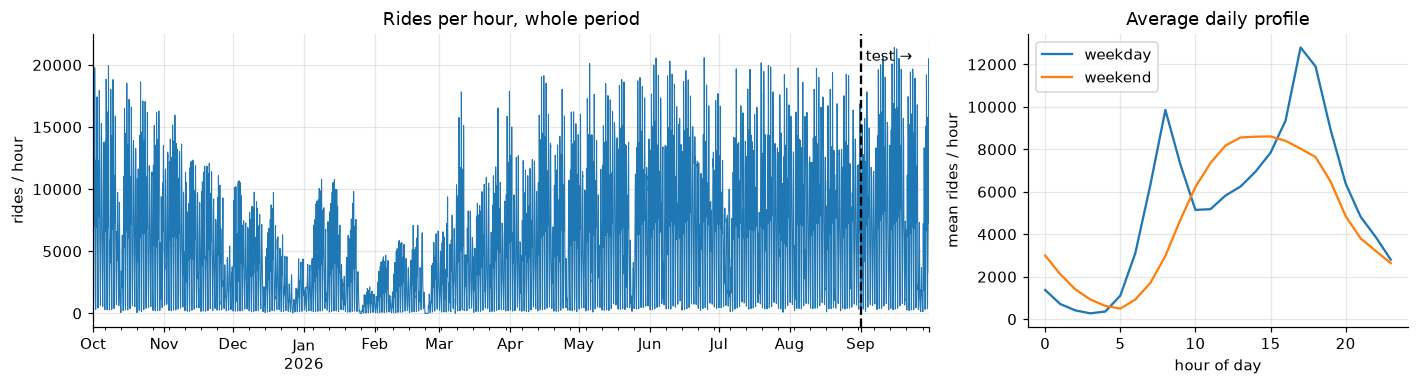

In [5]:
total = rides.groupby("hour").size().reindex(ALL_HOURS, fill_value=0)
members = rides.groupby("hour")["member"].sum().reindex(ALL_HOURS, fill_value=0)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
total.plot(ax=ax[0], lw=0.7)
ax[0].axvline(TEST_START, color="k", ls="--"); ax[0].text(TEST_START, total.max() * 0.95, " test →")
ax[0].set(title="Rides per hour, whole period", ylabel="rides / hour", xlabel="")

how = pd.DataFrame({"rides": total, "wkend": total.index.dayofweek >= 5, "h": total.index.hour})
for wk, g in how.groupby("wkend"):
    ax[1].plot(g.groupby("h").rides.mean(), label="weekend" if wk else "weekday")
ax[1].set(title="Average daily profile", xlabel="hour of day", ylabel="mean rides / hour"); ax[1].legend()
plt.tight_layout(); plt.show()

## 4. Naive HMM
### Zones
Two fixed rectangles: the Upper East Side (UES) and Midtown (MID). The station list uses training data only.

zone
outside    2366
MID          70
UES          54
Name: stations per zone, dtype: int64


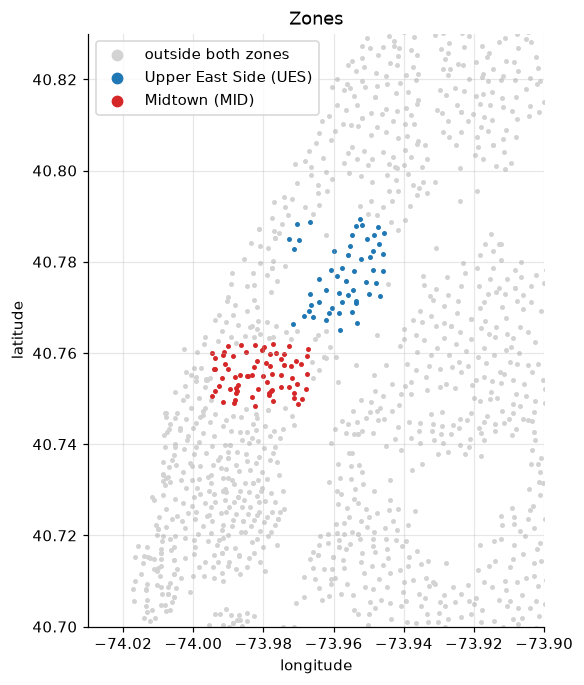

In [6]:
train_rides = rides[rides.hour < TEST_START]
ends = train_rides.s.value_counts().add(train_rides.e.value_counts(), fill_value=0)
active_days = train_rides.hour.dt.normalize().groupby(train_rides.s).nunique()
enough = (ends.reindex(station_coords.index).fillna(0) >= MIN_ENDPOINTS) & (active_days.reindex(station_coords.index).fillna(0) >= MIN_ACTIVE_DAYS)

coords = station_coords.assign(zone="outside")
for z, (lat0, lat1, lng0, lng1) in RECTS.items():
    inside = (coords.start_lat >= lat0) & (coords.start_lat < lat1) & (coords.start_lng >= lng0) & (coords.start_lng < lng1)
    coords.loc[inside & enough, "zone"] = z
zone_of = coords.zone.to_dict()
print(coords.zone.value_counts().rename("stations per zone"))

fig, ax = plt.subplots(figsize=(6, 7))
for z, c in [("outside", "lightgrey"), ("UES", "C0"), ("MID", "C3")]:
    g = coords[coords.zone == z]
    ax.scatter(g.start_lng, g.start_lat, s=5, c=c, label={"UES": "Upper East Side (UES)", "MID": "Midtown (MID)", "outside": "outside both zones"}[z])
ax.set(title="Zones", xlabel="longitude", ylabel="latitude", xlim=(-74.03, -73.90), ylim=(40.70, 40.83)); ax.legend(markerscale=3)
ax.set_aspect(1.3); plt.show()

### Ride types
Each ride gets one type, checked in order: round trip, UES→MID, MID→UES, within UES, within MID, other.

type
UES_to_MID    0.005
MID_to_UES    0.005
within_UES    0.015
within_MID    0.021
round_trip    0.020
other         0.933
Name: share of all rides, dtype: float64


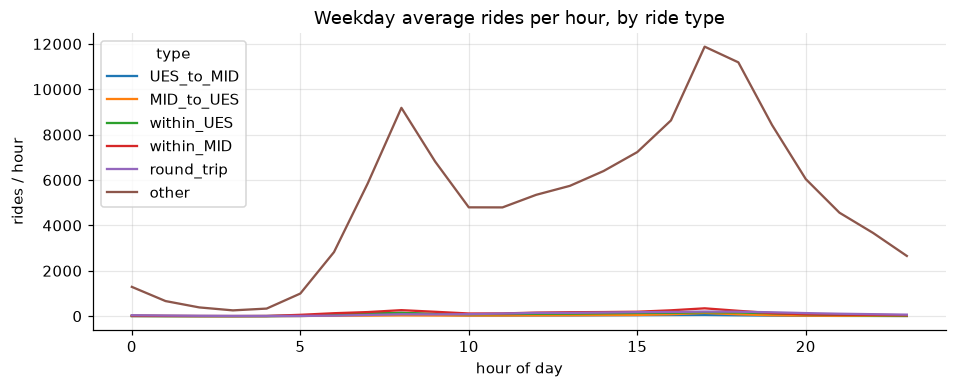

In [7]:
FEATURES = ["UES_to_MID", "MID_to_UES", "within_UES", "within_MID", "round_trip", "other"]
zs = rides.s.map(zone_of).fillna("outside").to_numpy(dtype=object)
ze = rides.e.map(zone_of).fillna("outside").to_numpy(dtype=object)
same = (rides.s == rides.e).to_numpy(dtype=bool)
rides["type"] = pd.Categorical(np.select(
    [same, (zs == "UES") & (ze == "MID"), (zs == "MID") & (ze == "UES"), (zs == "UES") & (ze == "UES"), (zs == "MID") & (ze == "MID")],
    ["round_trip", "UES_to_MID", "MID_to_UES", "within_UES", "within_MID"], default="other"), categories=FEATURES)

counts = (rides.groupby(["hour", "type"], observed=False).size().unstack(fill_value=0)
               .reindex(index=ALL_HOURS, columns=FEATURES, fill_value=0))
assert (counts.sum(axis=1).to_numpy() == total.to_numpy()).all()
print((counts.sum() / counts.to_numpy().sum()).rename("share of all rides").round(3))

wk = counts[counts.index.dayofweek < 5]
prof = wk.groupby(wk.index.hour).mean()
prof.plot(figsize=(10, 3.5), title="Weekday average rides per hour, by ride type")
plt.xlabel("hour of day"); plt.ylabel("rides / hour"); plt.show()

### Model
$$x_t \mid z_t=k \sim \prod_{f=1}^{6} \text{Poisson}(\lambda_{kf})$$
Fit with Baum-Welch (`hmmlearn`), keeping the best of 5 restarts by training log-likelihood. $K$ is chosen by an elbow rule on September 2026, the same month reported in sections 6–8. The full-year test in section 9 chooses $K$ on training data only.

In [8]:
class FullHistoryMonitor(ConvergenceMonitor):
    # keep the full log-likelihood curve
    def _reset(self):
        super()._reset(); self.full_history = []
    def report(self, log_prob):
        if not hasattr(self, "full_history"):
            self.full_history = []
        self.full_history.append(log_prob); super().report(log_prob)

def fit_poisson_hmm(X, K, seed, n_iter=500, tol=1e-2):
    # k-means init: random lambdas can leave a state empty and give NaNs
    model = hmm.PoissonHMM(n_components=K, n_iter=n_iter, tol=tol, random_state=seed, init_params="st")
    labels = KMeans(K, n_init=1, random_state=seed).fit_predict(np.log1p(X))
    model.lambdas_ = np.array([X[labels == k].mean(axis=0) for k in range(K)]) + 1e-3
    model.monitor_ = FullHistoryMonitor(tol, n_iter, False)
    t0 = time.perf_counter(); model.fit(X); model.fit_seconds_ = time.perf_counter() - t0
    model.history_ = list(model.monitor_.full_history)
    return model

def n_params(K, F):
    return (K - 1) + K * (K - 1) + K * F

def run_sweep(fit_fn, score_fn, Ks, F, T_train, n_restarts=N_RESTARTS, label=""):
    # best restart per K by training log-likelihood
    records, best = [], {}
    for K in Ks:
        for r in range(n_restarts):
            m = fit_fn(K, SEED + r)
            tr, te = score_fn(m, "train"), score_fn(m, "test")
            records.append(dict(K=K, restart=r, train_ll=tr, test_ll=te, iters=len(m.history_),
                                seconds=m.fit_seconds_, history=m.history_))
            if K not in best or tr > best[K][1]:
                best[K] = (m, tr)
        if label:
            print(f"{label} K={K}: best train LL {best[K][1]:,.0f}")
    runs = pd.DataFrame(records)
    summ = (runs.loc[runs.groupby("K").train_ll.idxmax(), ["K", "train_ll", "test_ll", "iters", "seconds"]]
               .set_index("K"))
    summ["BIC"] = -2 * summ.train_ll + np.array([n_params(K, F) for K in summ.index]) * np.log(T_train)
    summ["test_ll_per_hour"] = summ.test_ll / is_test.sum()
    return {K: b[0] for K, b in best.items()}, runs, summ

def choose_K(summ, frac=0.9):
    # elbow rule: smallest K reaching `frac` of the total gain
    gain = summ.test_ll - summ.test_ll.iloc[0]
    if gain.max() <= 0:
        return summ.index[0]
    return int(gain.index[gain >= frac * gain.max()][0])

def plot_elbow(summ, K, title, extra=None, frac=0.9):
    ll = summ.test_ll_per_hour
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    ax.plot(ll.index, ll, "o-", label="K searched")
    if extra is not None:
        more = pd.concat([ll.iloc[-1:], extra.test_ll_per_hour])
        ax.plot(more.index, more, "o--", color="grey", mfc="white", zorder=1, label="larger K, not searched")
    ax.axhline(ll.iloc[0] + frac * (ll.max() - ll.iloc[0]), color="k", ls=":", lw=1, label=f"{frac:.0%} of the gain over K searched")
    ax.plot(K, ll[K], "o", color="C3", ms=10, label=f"chosen K = {K}")
    ax.set(title=title, xlabel="K", ylabel="log-likelihood per hour"); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

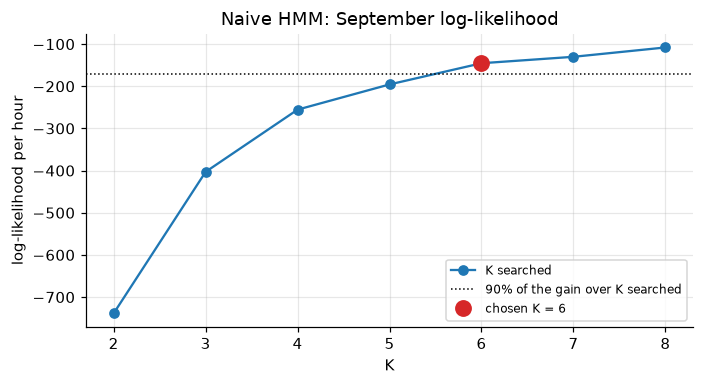

In [9]:
X_all = counts.to_numpy().astype(int)
X_tr, X_te = X_all[~is_test], X_all[is_test]

models_naive, runs_naive, summ_naive = run_sweep(
    fit_fn=lambda K, s: fit_poisson_hmm(X_tr, K, s),
    score_fn=lambda m, part: m.score(X_tr if part == "train" else X_te),
    Ks=K_RANGE_HMMLEARN, F=len(FEATURES), T_train=len(X_tr))
K_naive = choose_K(summ_naive)
plot_elbow(summ_naive, K_naive, "Naive HMM: September log-likelihood")

In [10]:
def relabel_by(values):
    order = np.argsort(values); rank = np.empty_like(order); rank[order] = np.arange(len(order)); return rank

def occupancy_heatmap(states, K, title, names=None):
    df = pd.DataFrame({"z": states, "h": ALL_HOURS.hour, "wk": ALL_HOURS.dayofweek >= 5})
    fig, axes = plt.subplots(1, 2, figsize=(13, 0.45 * K + 1.6), sharey=True)
    for ax, (wk, g) in zip(axes, df.groupby("wk")):
        occ = pd.crosstab(g.z, g.h, normalize="columns").reindex(range(K), fill_value=0)
        im = ax.imshow(occ, aspect="auto", cmap="Blues", vmin=0, vmax=1)
        ax.set(title=("weekend" if wk else "weekday"), xlabel="hour of day", xticks=range(0, 24, 3))
        ax.grid(False)
    axes[0].set_yticks(range(K), names if names is not None else [f"state {k}" for k in range(K)])
    fig.colorbar(im, ax=axes, label="share of hours in state", fraction=0.025)
    fig.suptitle(title); plt.show()

,UES_to_MID,MID_to_UES,within_UES,within_MID,round_trip,other,total rides/h,member share (held out)
"S0: 409/h, most over-rep: round_trip",0.47,0.63,0.83,1.12,1.43,1.00,409.10,0.81
"S1: 1,554/h, most over-rep: within_MID",0.68,0.80,1.05,1.14,1.10,1.00,1554.36,0.84
"S2: 3,718/h, most over-rep: within_MID",0.92,0.86,1.10,1.10,0.93,1.00,3718.01,0.86
"S3: 6,549/h, most over-rep: within_UES",1.02,0.92,1.06,1.02,0.99,1.00,6549.47,0.84
"S4: 9,748/h, most over-rep: UES_to_MID",1.12,0.99,1.02,0.99,1.00,1.00,9747.62,0.82
"S5: 14,631/h, most over-rep: MID_to_UES",1.00,1.25,0.93,0.92,1.00,1.00,14631.05,0.81


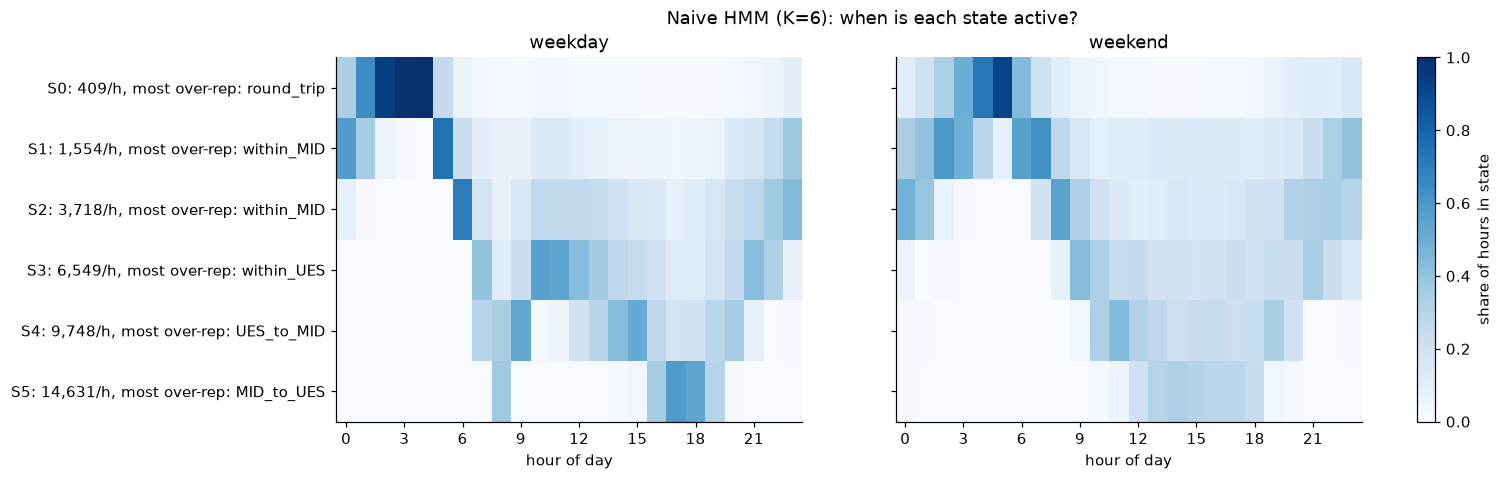

In [11]:
m_naive = models_naive[K_naive]
lam_naive = m_naive.lambdas_
rank_naive = relabel_by(lam_naive.sum(1))
lam_naive = lam_naive[np.argsort(lam_naive.sum(1))]
z_naive = rank_naive[m_naive.predict(X_all)]

share = lam_naive / lam_naive.sum(1, keepdims=True)
overall = X_all.sum(0) / X_all.sum()
lift = share / overall
member_share = pd.Series(members.to_numpy()).groupby(z_naive).sum() / pd.Series(total.to_numpy()).groupby(z_naive).sum()

def auto_name(k):
    top = FEATURES[int(np.argmax(lift[k]))]
    return f"S{k}: {lam_naive[k].sum():,.0f}/h, most over-rep: {top}"
names_naive = [auto_name(k) for k in range(K_naive)]

fp = pd.DataFrame(lift, columns=FEATURES, index=names_naive)
fp["total rides/h"] = lam_naive.sum(1); fp["member share (held out)"] = member_share.reindex(range(K_naive)).to_numpy()
display(fp.style.background_gradient(cmap="RdBu_r", subset=FEATURES, vmin=0, vmax=2).format("{:.2f}"))
occupancy_heatmap(z_naive, K_naive, f"Naive HMM (K={K_naive}): when is each state active?", names_naive)

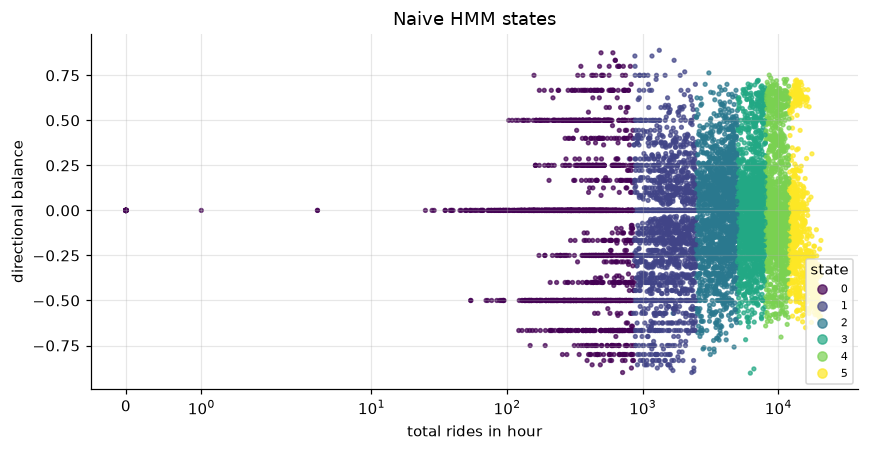

In [12]:
bal = (counts.UES_to_MID - counts.MID_to_UES) / (counts.UES_to_MID + counts.MID_to_UES + 1)
fig, ax = plt.subplots(figsize=(8, 4.2))
sc = ax.scatter(total, bal, c=z_naive, cmap="viridis", s=6, alpha=0.7, vmin=0, vmax=K_naive - 1)
ax.set(title="Naive HMM states", xlabel="total rides in hour", ylabel="directional balance"); ax.set_xscale("symlog")
ax.legend(*sc.legend_elements(), title="state", fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

## 5. Forward filtering and Viterbi
Implemented from scratch and checked against `hmmlearn`. Forecasts use filtered probabilities, which only depend on past hours.

In [13]:
def poisson_log_emissions(X, lam):
    # X: (T,F), lam: (K,F) or (T,K,F) -> (T,K)
    lam = np.maximum(lam, 1e-10)
    if lam.ndim == 2:
        lam = lam[None]
    return (X[:, None, :] * np.log(lam) - lam - gammaln(X + 1)[:, None, :]).sum(-1)

def forward_filter(logB, startprob, transmat):
    # log space; returns P(z_t | x_1..t) and log P(x_1..T)
    T, K = logB.shape
    with np.errstate(divide="ignore"):
        log_prior, logA = np.log(startprob), np.log(transmat)
    filt, loglik = np.empty((T, K)), 0.0
    for t in range(T):
        lw = log_prior + logB[t]
        norm = logsumexp(lw)
        loglik += norm
        log_filt = lw - norm
        filt[t] = np.exp(log_filt)
        log_prior = logsumexp(log_filt[:, None] + logA, axis=0)
    return filt, loglik

def viterbi(logB, startprob, transmat):
    T, K = logB.shape
    with np.errstate(divide="ignore"):
        log_start, logA = np.log(startprob), np.log(transmat)
    delta = log_start + logB[0]; back = np.zeros((T, K), dtype=int)
    for t in range(1, T):
        cand = delta[:, None] + logA                 # (from, to)
        back[t] = cand.argmax(0); delta = cand.max(0) + logB[t]
    path = np.empty(T, dtype=int); path[-1] = delta.argmax()
    for t in range(T - 1, 0, -1):
        path[t - 1] = back[t, path[t]]
    return path

# check against hmmlearn
logB_naive = poisson_log_emissions(X_all.astype(float), m_naive.lambdas_)
filt_naive, ll_ours = forward_filter(logB_naive, m_naive.startprob_, m_naive.transmat_)
print(f"log P(x) ours = {ll_ours:,.3f}   hmmlearn = {m_naive.score(X_all):,.3f}")
assert np.isclose(ll_ours, m_naive.score(X_all), rtol=1e-6)
agree = (viterbi(logB_naive, m_naive.startprob_, m_naive.transmat_) == m_naive.predict(X_all)).mean()
print(f"Viterbi path agreement with hmmlearn: {agree:.1%}")

log P(x) ours = -1,053,727.022   hmmlearn = -1,053,727.022
Viterbi path agreement with hmmlearn: 100.0%


## 6. Naive HMM vs. baselines
Baselines: hour-of-week mean, persistence, activity-adjusted average and 24-hour ratio.

In [14]:
how_key = lambda idx: idx.dayofweek * 24 + idx.hour
train_counts = counts[~is_test]
how_means = train_counts.groupby(how_key(train_counts.index)).mean()
B_how = how_means.reindex(how_key(ALL_HOURS)).to_numpy()

def targets(F6):
    F6 = np.asarray(F6, float)
    return {"total": F6.sum(1), "UES_to_MID": F6[:, 0], "MID_to_UES": F6[:, 1], "net_into_MID": F6[:, 0] - F6[:, 1]}

def hmm_forecast(filt, transmat, rate_fn, h):
    P = np.full_like(filt, np.nan)
    P[h:] = filt[:-h] @ np.linalg.matrix_power(transmat, h)     # P(z_t | x_1..t-h)
    return rate_fn(P)

def persistence(X, h):
    out = np.full(X.shape, np.nan); out[h:] = X[:-h]; return out

def activity_adjusted(X, h, train_mask, hours, ratio_cols=slice(None)):
    # weekday/weekend profile * (rides so far today / usual rides so far)
    X, wk, hr = np.asarray(X, float), (hours.dayofweek >= 5).astype(int), hours.hour.to_numpy()
    prof = np.stack([[X[train_mask & (wk == g) & (hr == k)].mean(0) for k in range(24)] for g in (0, 1)])
    usual = np.concatenate([np.zeros((2, 1)), prof[:, :, ratio_cols].sum(-1).cumsum(1)], axis=1)
    days = X[:, ratio_cols].sum(1).reshape(-1, 24)
    seen = np.concatenate([np.zeros((len(days), 1)), days.cumsum(1)], axis=1)
    c = np.maximum(hr - h + 1, 0)    # hours of today already seen
    ob, ex = seen[np.arange(len(X)) // 24, c], usual[wk, c]
    ratio = np.divide(ob, ex, out=np.ones_like(ob), where=(c > 0) & (ex > 0))
    return ratio[:, None] * prof[wk, hr]

def ratio_24h(X, B, h, ratio_cols=slice(None)):
    # clock baseline * (rides in the last 24 hours / usual rides in those hours)
    X, B = np.asarray(X, float), np.asarray(B, float)
    last24 = lambda A: pd.Series(A[:, ratio_cols].sum(1)).rolling(24).sum().shift(h).to_numpy()
    ob, ex = last24(X), last24(B)
    ratio = np.divide(ob, ex, out=np.full_like(ob, np.nan), where=ex > 0)
    return ratio[:, None] * B

actual = targets(X_all)

def evaluate(forecasters, horizons):
    rows = []
    for h in horizons:
        for name, fn in forecasters.items():
            pred = fn(h)
            for tgt, y in actual.items():
                if tgt in pred:
                    rows.append(dict(h=h, method=name, target=tgt, MAE=np.nanmean(np.abs(pred[tgt][is_test] - y[is_test]))))
    return pd.DataFrame(rows)

forecasters = {
    "hour-of-week mean": lambda h: targets(B_how),
    "persistence":       lambda h: targets(persistence(X_all, h)),
    "activity-adjusted": lambda h: targets(activity_adjusted(X_all, h, ~is_test, ALL_HOURS)),
    "24h ratio":         lambda h: targets(ratio_24h(X_all, B_how, h)),
    "naive HMM": lambda h: targets(hmm_forecast(filt_naive, m_naive.transmat_, lambda P: P @ m_naive.lambdas_, h)),
}
res_naive = evaluate(forecasters, HORIZONS)
display(res_naive[res_naive.h == 1].pivot(index="method", columns="target", values="MAE")[list(actual)].round(1))

target,total,UES_to_MID,MID_to_UES,net_into_MID
method,,,,
24h ratio,898.0,8.0,7.7,8.8
activity-adjusted,844.4,7.5,7.9,9.6
hour-of-week mean,2447.7,13.3,13.3,11.0
naive HMM,1912.3,22.3,20.7,21.4
persistence,1766.6,17.0,16.0,21.5


## 7. Clock-aware HMM
$$x_{tf} \mid z_t=k \sim \text{Poisson}(b_{tf}\, m_{kf})$$
$b_{tf}$ is the hour-of-week mean and $m_{kf}$ a state multiplier. The M-step has a closed form:
$$m_{kf} = \frac{\sum_t \gamma_t(k)\, x_{tf}}{\sum_t \gamma_t(k)\, b_{tf}}$$

In [15]:
class ClockAwarePoissonHMM:

    def __init__(self, n_components, n_iter=300, tol=1e-2, random_state=0):
        self.K, self.n_iter, self.tol, self.random_state = n_components, n_iter, tol, random_state

    def _init(self, X, B):
        rng = np.random.default_rng(self.random_state)
        K, F = self.K, X.shape[1]
        ratio = X.sum(1) / B.sum(1)
        levels = np.quantile(ratio, (np.arange(K) + 0.5) / K)
        self.multipliers_ = levels[:, None] * rng.uniform(0.85, 1.15, (K, F))
        self.startprob_ = np.full(K, 1 / K)
        A = rng.uniform(0.5, 1.5, (K, K)) + 5 * K * np.eye(K)    # sticky start
        self.transmat_ = A / A.sum(1, keepdims=True)

    def log_emissions(self, X, B):
        return poisson_log_emissions(X, B[:, None, :] * self.multipliers_[None, :, :])

    def _forward_backward(self, logB):
        T, K = logB.shape; A = self.transmat_
        mx = logB.max(1, keepdims=True); b = np.exp(logB - mx)    # rescale to avoid underflow
        alpha, c = np.empty((T, K)), np.empty(T)
        alpha[0] = self.startprob_ * b[0]; c[0] = alpha[0].sum(); alpha[0] /= c[0]
        for t in range(1, T):
            alpha[t] = (alpha[t - 1] @ A) * b[t]; c[t] = alpha[t].sum(); alpha[t] /= c[t]
        beta = np.ones((T, K))
        for t in range(T - 2, -1, -1):
            beta[t] = A @ (b[t + 1] * beta[t + 1]) / c[t + 1]
        gamma = alpha * beta; gamma /= gamma.sum(1, keepdims=True)
        xi_sum = A * (alpha[:-1].T @ (b[1:] * beta[1:] / c[1:, None]))
        return gamma, xi_sum, np.log(c).sum() + mx.sum()

    def fit(self, X, B):
        X, B = np.asarray(X, float), np.maximum(np.asarray(B, float), 1e-3)
        self._init(X, B); self.history_ = []
        t0 = time.perf_counter()
        for it in range(self.n_iter):
            gamma, xi_sum, ll = self._forward_backward(self.log_emissions(X, B))
            self.history_.append(ll)
            if it > 0 and ll - self.history_[-2] < self.tol:
                break
            # M-step
            self.startprob_ = (gamma[0] + 1e-6) / (gamma[0] + 1e-6).sum()
            self.transmat_ = (xi_sum + 1e-6) / (xi_sum + 1e-6).sum(1, keepdims=True)
            self.multipliers_ = np.maximum((gamma.T @ X) / (gamma.T @ B), 1e-6)
        self.fit_seconds_ = time.perf_counter() - t0
        h = np.array(self.history_)
        assert np.all(np.diff(h) >= -1e-6 * np.abs(h[:-1])), "EM log-likelihood decreased: bug!"
        return self

    def score(self, X, B):
        return forward_filter(self.log_emissions(np.asarray(X, float), np.maximum(B, 1e-3)), self.startprob_, self.transmat_)[1]

    def filter(self, X, B):
        return forward_filter(self.log_emissions(np.asarray(X, float), np.maximum(B, 1e-3)), self.startprob_, self.transmat_)[0]

    def decode(self, X, B):
        return viterbi(self.log_emissions(np.asarray(X, float), np.maximum(B, 1e-3)), self.startprob_, self.transmat_)

With $b_{tf}=1$ this reduces to an ordinary Poisson HMM, so it should match `hmmlearn` closely.

In [16]:
ones = np.ones_like(X_tr, dtype=float)
ours = max((ClockAwarePoissonHMM(K_naive, random_state=SEED + r).fit(X_tr, ones) for r in range(N_RESTARTS)), key=lambda m: m.history_[-1])
print(f"K={K_naive}, baseline=1   our EM: {ours.score(X_tr, ones):,.1f}   hmmlearn: {models_naive[K_naive].score(X_tr):,.1f}")

K=6, baseline=1   our EM: -949,590.7   hmmlearn: -950,385.2


clock-aware K=2: best train LL -1,767,229


clock-aware K=3: best train LL -978,645


clock-aware K=4: best train LL -724,632


clock-aware K=5: best train LL -561,447


clock-aware K=6: best train LL -467,237


,test_ll,iters,seconds,BIC,test_ll_per_hour
K,,,,,
2,-114007.389,12,0.329,3.535e+06,-158.344
3,-77606.528,20,0.573,1.958e+06,-107.787
4,-57632.270,43,1.240,1.450e+06,-80.045
5,-47730.516,81,2.374,1.123e+06,-66.292
6,-38315.103,49,1.545,9.351e+05,-53.215


BIC-optimal K: 6 | elbow-chosen K: 6


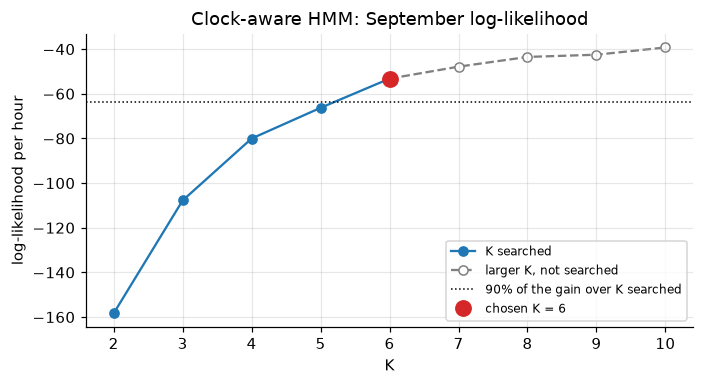

held-out LL/hour  naive (K=6): -145.4   clock baseline alone: -652.5   clock-aware (K=6): -53.2


In [17]:
B_tr, B_te = B_how[~is_test], B_how[is_test]
models_clock, runs_clock, summ_clock = run_sweep(
    fit_fn=lambda K, s: ClockAwarePoissonHMM(K, random_state=s).fit(X_tr, B_tr),
    score_fn=lambda m, part: m.score(X_tr, B_tr) if part == "train" else m.score(X_te, B_te),
    Ks=K_RANGE_CLOCK, F=len(FEATURES), T_train=len(X_tr), label="clock-aware")
K_clock = choose_K(summ_clock)
display(summ_clock.drop(columns=["train_ll"]))
print("BIC-optimal K:", summ_clock.BIC.idxmin(), "| elbow-chosen K:", K_clock)

# larger K for the plot only
_, _, summ_larger = run_sweep(
    fit_fn=lambda K, s: ClockAwarePoissonHMM(K, random_state=s).fit(X_tr, B_tr),
    score_fn=lambda m, part: m.score(X_tr, B_tr) if part == "train" else m.score(X_te, B_te),
    Ks=range(max(K_RANGE_CLOCK) + 1, 11), F=len(FEATURES), T_train=len(X_tr))
plot_elbow(summ_clock, K_clock, "Clock-aware HMM: September log-likelihood", extra=summ_larger)

# clock baseline alone, no hidden state
base_te = poisson_log_emissions(X_te.astype(float), np.maximum(B_te, 1e-3)[:, None, :])[:, 0].sum()
print(f"held-out LL/hour  naive (K={K_naive}): {summ_naive.loc[K_naive, 'test_ll_per_hour']:.1f}   "
      f"clock baseline alone: {base_te / is_test.sum():.1f}   clock-aware (K={K_clock}): {summ_clock.loc[K_clock, 'test_ll_per_hour']:.1f}")

,UES_to_MID,MID_to_UES,within_UES,within_MID,round_trip,other,share of hours,member share (held out)
S0: avg ×0.15,0.11,0.12,0.16,0.18,0.17,0.14,0.06,0.91
S1: avg ×0.39,0.34,0.35,0.44,0.48,0.35,0.39,0.12,0.90
S2: avg ×0.68,0.63,0.68,0.76,0.80,0.55,0.68,0.18,0.88
S3: avg ×0.99,0.97,0.99,1.03,1.04,0.90,1.00,0.17,0.85
S4: avg ×1.33,1.36,1.35,1.28,1.27,1.38,1.34,0.28,0.83
S5: avg ×1.65,1.74,1.66,1.56,1.46,1.85,1.65,0.18,0.78


Transition matrix (rows = from, sorted states):


,S0: avg ×0.15,S1: avg ×0.39,S2: avg ×0.68,S3: avg ×0.99,S4: avg ×1.33,S5: avg ×1.65
S0: avg ×0.15,0.869,0.124,0.004,0.000,0.004,0.000
S1: avg ×0.39,0.062,0.811,0.121,0.005,0.000,0.000
S2: avg ×0.68,0.004,0.074,0.825,0.094,0.003,0.001
S3: avg ×0.99,0.000,0.005,0.089,0.792,0.112,0.003
S4: avg ×1.33,0.000,0.002,0.005,0.070,0.843,0.079
S5: avg ×1.65,0.000,0.001,0.002,0.004,0.131,0.863


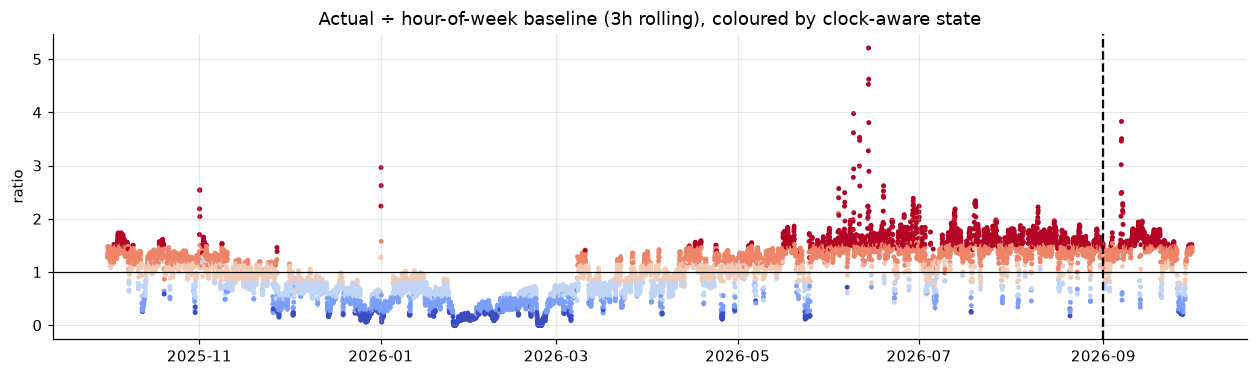

In [18]:
m_clock = models_clock[K_clock]
rank_clock = relabel_by(m_clock.multipliers_.mean(1))
mult_clock = m_clock.multipliers_[np.argsort(m_clock.multipliers_.mean(1))]
z_clock = rank_clock[m_clock.decode(X_all, B_how)]
names_clock = [f"S{k}: avg ×{mult_clock[k].mean():.2f}" for k in range(K_clock)]

tbl = pd.DataFrame(mult_clock, index=names_clock, columns=FEATURES)
tbl["share of hours"] = np.bincount(z_clock, minlength=K_clock) / len(z_clock)
tbl["member share (held out)"] = (pd.Series(members.to_numpy()).groupby(z_clock).sum() / pd.Series(total.to_numpy()).groupby(z_clock).sum()).reindex(range(K_clock)).to_numpy()
display(tbl.style.background_gradient(cmap="RdBu_r", subset=FEATURES, vmin=0, vmax=2).format("{:.2f}"))
print("Transition matrix (rows = from, sorted states):")
display(pd.DataFrame(m_clock.transmat_[np.ix_(np.argsort(m_clock.multipliers_.mean(1)), np.argsort(m_clock.multipliers_.mean(1)))],
                     index=names_clock, columns=names_clock).round(3))

ratio = pd.Series(X_all.sum(1) / B_how.sum(1), index=ALL_HOURS).rolling(3, center=True).mean()
fig, ax = plt.subplots(figsize=(14, 3.6))
ax.scatter(ALL_HOURS, ratio, c=z_clock, cmap="coolwarm", s=5, vmin=0, vmax=K_clock - 1)
ax.axhline(1, color="k", lw=0.8)
ax.axvline(TEST_START, color="k", ls="--")
ax.set(title="Actual ÷ hour-of-week baseline (3h rolling), coloured by clock-aware state", ylabel="ratio")
plt.show()

### States of the two models

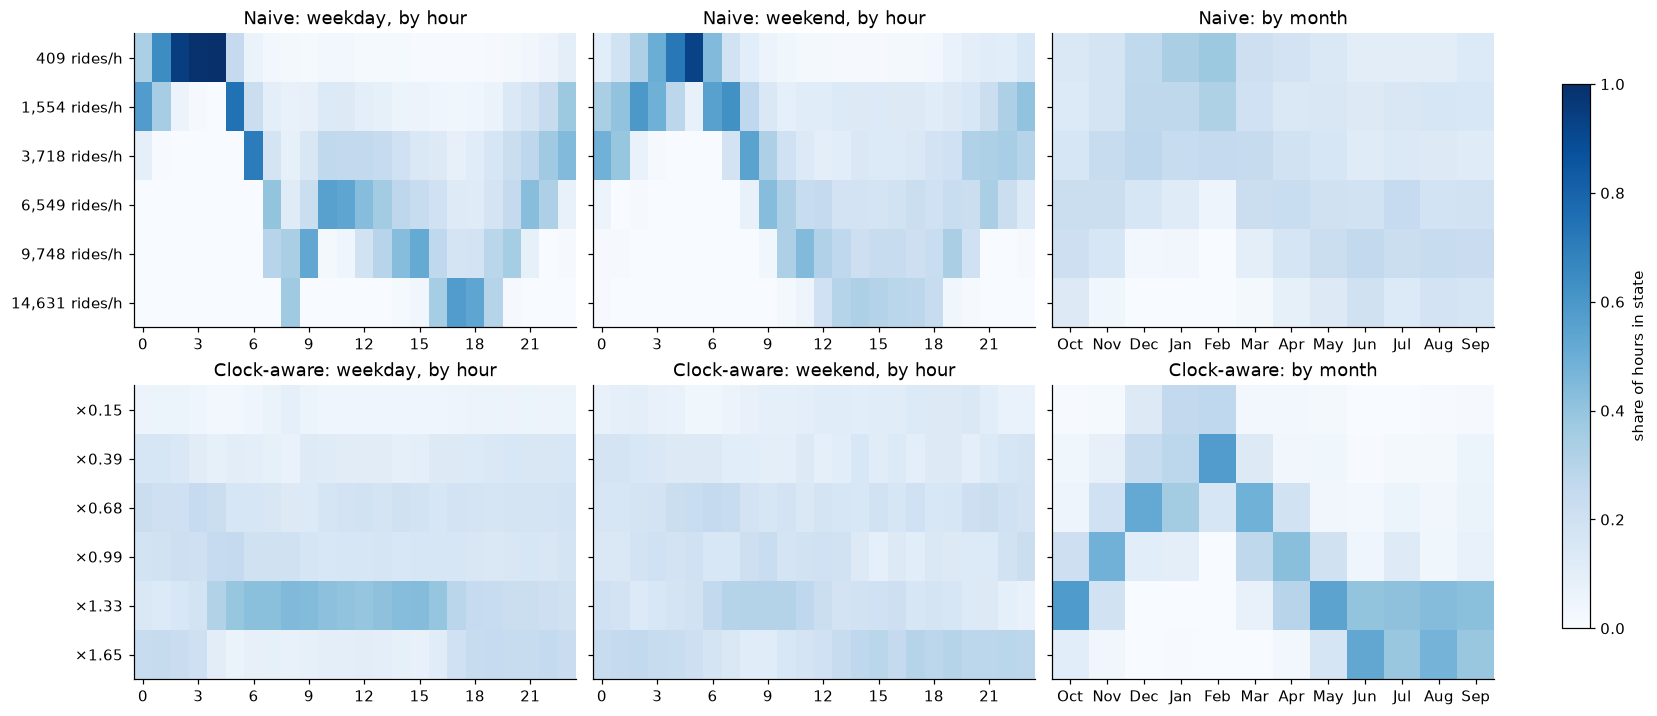

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(15, 6.4), sharey="row", layout="constrained")
wk, hr, months = ALL_HOURS.dayofweek >= 5, ALL_HOURS.hour, ALL_HOURS.to_period("M")
for row, z, K, names, model in [(axes[0], z_naive, K_naive, [f"{l:,.0f} rides/h" for l in lam_naive.sum(1)], "Naive"),
                                (axes[1], z_clock, K_clock, [f"×{m:.2f}" for m in mult_clock.mean(1)], "Clock-aware")]:
    for ax, mask, by, label in [(row[0], ~wk, hr, "weekday, by hour"), (row[1], wk, hr, "weekend, by hour"), (row[2], wk | ~wk, months, "by month")]:
        occ = pd.crosstab(z[mask], by[mask], normalize="columns").reindex(range(K), fill_value=0)
        im = ax.imshow(occ, aspect="auto", cmap="Blues", vmin=0, vmax=1)
        ax.set_title(f"{model}: {label}"); ax.grid(False)
        if by is hr:
            ax.set_xticks(range(0, 24, 3))
        else:
            ax.set_xticks(range(len(occ.columns)), [p.strftime("%b") for p in occ.columns])
    row[0].set_yticks(range(K), names)
fig.colorbar(im, ax=axes, label="share of hours in state", fraction=0.02)
plt.show()

## 8. Forecasts for September 2026

MAE at h = 1 hour ahead (rides/hour, test weeks; lower is better)


target,total,UES_to_MID,MID_to_UES,net_into_MID
method,,,,
24h ratio,898.0,8.0,7.7,8.8
activity-adjusted,844.4,7.5,7.9,9.6
clock-aware HMM,579.3,6.5,6.6,8.4
hour-of-week mean,2447.7,13.3,13.3,11.0
naive HMM,1912.3,22.3,20.7,21.4
persistence,1766.6,17.0,16.0,21.5


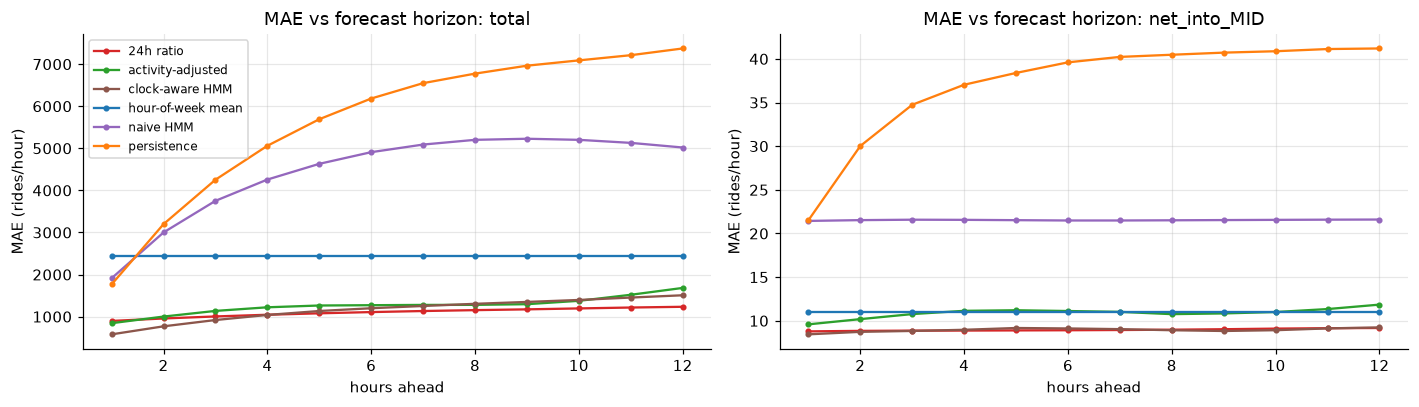

In [20]:
filt_clock = m_clock.filter(X_all, B_how)
forecasters["clock-aware HMM"] = lambda h: targets(B_how * hmm_forecast(filt_clock, m_clock.transmat_, lambda P: P @ m_clock.multipliers_, h))
res = evaluate(forecasters, HORIZONS)

print("MAE at h = 1 hour ahead (rides/hour, test weeks; lower is better)")
display(res[res.h == 1].pivot(index="method", columns="target", values="MAE")[list(actual)].round(1))

COLORS = {m: f"C{i}" for i, m in enumerate(forecasters)}
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, tgt in zip(ax, ["total", "net_into_MID"]):
    for name, g in res[res.target == tgt].groupby("method"):
        a.plot(g.h, g.MAE, "o-", ms=3, label=name, color=COLORS[name])
    a.set(title=f"MAE vs forecast horizon: {tgt}", xlabel="hours ahead", ylabel="MAE (rides/hour)")
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 9. Full-year test
Each month from Oct 2025 to Sep 2026 is forecast by a model trained on the previous 12 months, with zones, baselines and $K$ recomputed each time. Two tasks:
* **Noon:** forecast hours 12–23 at noon.
* **Rolling:** forecast every hour from 1–12 hours earlier.

In [21]:
WF_START = pd.Timestamp(HISTORY_MONTHS[0] + "01")
WF_TESTS = pd.period_range(MONTHS[0], MONTHS[-1], freq="M")
DST_DATES = pd.to_datetime(["2024-11-03", "2025-03-09", "2025-11-02", "2026-03-08"])

# both years as integer codes to save memory
history, history_coords = load_rides(HISTORY_MONTHS)
history = history[(history.hour >= WF_START) & (history.hour < PERIOD_START)]
stations = pd.Index(pd.concat([history.s, history.e, rides.s, rides.e]).unique())
code = lambda col: np.concatenate([stations.get_indexer(d[col]) for d in (history, rides)]).astype(np.int32)
wf_s, wf_e = code("s"), code("e")
wf_h = np.concatenate([((d.hour - WF_START) // pd.Timedelta("1h")).to_numpy() for d in (history, rides)]).astype(np.int32)
wf_xy = station_coords[["start_lat", "start_lng"]].combine_first(history_coords[["start_lat", "start_lng"]]).reindex(stations).to_numpy()
print(history.groupby(history.hour.dt.to_period("M")).size().rename("history rides per month"))
print(f"{len(wf_s):,} rides, {len(stations):,} stations ({np.isnan(wf_xy[:, 0]).sum()} without coordinates)")
del history

def fold_counts(test):
    # hourly ride-type counts for 12 training months + the test month
    start, test_start, end = (test - 12).start_time, test.start_time, (test + 1).start_time
    hours = pd.date_range(start, end, freq="h", inclusive="left"); T, n = len(hours), len(stations)
    off = int((start - WF_START) / pd.Timedelta("1h"))
    keep = (wf_h >= off) & (wf_h < off + T)
    s, e, t = wf_s[keep], wf_e[keep], wf_h[keep] - off
    train_hour = hours < test_start
    tr = train_hour[t]
    ends = np.bincount(s[tr], minlength=n) + np.bincount(e[tr], minlength=n)
    active = np.bincount(np.unique(s[tr].astype(np.int64) * 1000 + t[tr] // 24) // 1000, minlength=n)
    zone, (lat, lng) = np.zeros(n, int), wf_xy.T    # 1 = UES, 2 = MID
    for z, (lat0, lat1, lng0, lng1) in zip((1, 2), RECTS.values()):
        zone[(lat >= lat0) & (lat < lat1) & (lng >= lng0) & (lng < lng1) & (ends >= MIN_ENDPOINTS) & (active >= MIN_ACTIVE_DAYS)] = z
    a, b = zone[s], zone[e]
    typ = np.select([s == e, (a == 1) & (b == 2), (a == 2) & (b == 1), (a == 1) & (b == 1), (a == 2) & (b == 2)],
                    [4, 0, 1, 2, 3], 5)    # same order as FEATURES
    return np.bincount(t.astype(np.int64) * 6 + typ, minlength=T * 6).reshape(T, 6).astype(float), (zone == 1).sum(), (zone == 2).sum()

t0 = time.perf_counter()
fold_data = {test: fold_counts(test) for test in WF_TESTS}
print(f"built {len(fold_data)} folds in {time.perf_counter() - t0:.0f}s")
del wf_s, wf_e, wf_h

loaded cache 202410_202509


hour
2024-10    5133307
2024-11    3696497
2024-12    2302858
2025-01    2119764
2025-02    2026077
2025-03    3158596
2025-04    3714220
2025-05    4311705
2025-06    4740549
2025-07    4964730
2025-08    5107407
2025-09    5271862
Freq: M, Name: history rides per month, dtype: int64
91,774,512 rides, 2,674 stations (101 without coordinates)


built 12 folds in 20s


In [22]:
HMM_, HOW_, PER_, ACT_, R24_ = "clock-aware HMM", "hour-of-week mean", "persistence", "activity-adjusted", "24h ratio"
WF_BASELINES = [HOW_, PER_, ACT_, R24_]
WF_METHODS = WF_BASELINES + [HMM_]

def run_fold(test, X, n_ues, n_mid):
    hours = pd.date_range((test - 12).start_time, (test + 1).start_time, freq="h", inclusive="left")
    is_te, is_va = hours >= test.start_time, (hours >= (test - 1).start_time) & (hours < test.start_time)
    is_tr = ~is_te; is_fit = is_tr & ~is_va
    key = hours.dayofweek * 24 + hours.hour
    clock = lambda mask: pd.DataFrame(X[mask]).groupby(key[mask]).mean().reindex(key).to_numpy()
    best = lambda K, mask, B: max((ClockAwarePoissonHMM(K, random_state=SEED + r).fit(X[mask], B[mask]) for r in range(N_RESTARTS)),
                                  key=lambda m: m.history_[-1])
    # choose K on the last training month, then refit on all 12
    B_fit, val_ll = clock(is_fit), {}
    for K in K_RANGE_CLOCK:
        m = best(K, is_fit, B_fit)
        val_ll[K] = m.score(X[is_tr], B_fit[is_tr]) - m.score(X[is_fit], B_fit[is_fit])
    K = choose_K(pd.Series(val_ll, name="test_ll").to_frame())
    B = clock(is_tr)
    m = best(K, is_tr, B); filt = m.filter(X, B)

    dst = hours.normalize().isin(DST_DATES)
    Y, te, rows = X[:, :2], np.flatnonzero(is_te & ~dst), []
    fit_days = is_tr & ~dst
    for h in HORIZONS:
        pred = {HOW_: B[te, :2], PER_: Y[te - h], ACT_: activity_adjusted(Y, h, fit_days, hours)[te], R24_: ratio_24h(Y, B[:, :2], h)[te],
                HMM_: (B[te] * (filt[te - h] @ np.linalg.matrix_power(m.transmat_, h) @ m.multipliers_))[:, :2]}
        for name, p in pred.items():
            d, hr = p - Y[te], hours[te]
            rows.append(pd.DataFrame(dict(method=name, h=h, time=hr, abs=np.abs(d).sum(1), sq=(d ** 2).sum(1),
                                          net=np.abs(d[:, 0] - d[:, 1]), pred=p.sum(1), actual=Y[te].sum(1))))
    info = dict(test=str(test), K=K, stations_UES=n_ues, stations_MID=n_mid,
                multipliers=np.round(np.sort(m.multipliers_.mean(1)), 2).tolist(), filt_nan=bool(np.isnan(filt).any()))
    return pd.concat(rows, ignore_index=True), info

from joblib import Parallel, delayed
t0 = time.perf_counter()
done = Parallel(n_jobs=WF_JOBS)(delayed(run_fold)(test, *v) for test, v in fold_data.items())
wf = pd.concat([r for r, _ in done], ignore_index=True)
wf_info = pd.DataFrame([i for _, i in done])
assert not wf.isna().any().any() and not wf_info.filt_nan.any()
wf["month"], wf["week"], wf["date"] = wf.time.dt.to_period("M"), wf.time.dt.to_period("W"), wf.time.dt.normalize()
print(f"{len(done)} folds in {time.perf_counter() - t0:.0f}s, {wf.date.nunique()} test days")
display(wf_info.drop(columns="filt_nan").set_index("test"))

# the noon task is a subset of the rolling rows
noon = wf[wf.time.dt.hour - wf.h == 11]

12 folds in 127s, 363 test days


,K,stations_UES,stations_MID,multipliers
test,,,,
2025-10,5,57,75,"[0.31, 0.59, 0.89, 1.22, 1.44]"
2025-11,5,57,75,"[0.31, 0.59, 0.9, 1.22, 1.46]"
2025-12,5,57,73,"[0.32, 0.6, 0.9, 1.23, 1.47]"
2026-01,5,57,73,"[0.28, 0.58, 0.89, 1.23, 1.47]"
2026-02,5,57,73,"[0.21, 0.53, 0.86, 1.22, 1.47]"
2026-03,6,57,74,"[0.14, 0.38, 0.66, 0.95, 1.28, 1.52]"
2026-04,5,56,74,"[0.15, 0.4, 0.72, 1.08, 1.43]"
2026-05,5,52,70,"[0.15, 0.41, 0.73, 1.12, 1.44]"
2026-06,6,52,69,"[0.14, 0.38, 0.66, 0.94, 1.27, 1.52]"


### Noon task
Percentages are error reductions relative to each baseline (positive is better).

In [23]:
def metrics(g):
    n = len(g)
    return pd.Series({"MAE": g["abs"].sum() / (2 * n), "RMSE": np.sqrt(g["sq"].sum() / (2 * n)), "net MAE": g["net"].mean(),
                      "bias %": 100 * (g.pred.sum() / g.actual.sum() - 1)})

def table(df, by):
    return df.groupby(["method", *by])[["abs", "sq", "net", "pred", "actual"]].apply(metrics)

t = table(noon, []).loc[WF_METHODS]
for b in WF_BASELINES:
    t[f"MAE vs {b}"] = 100 * (1 - t["MAE"] / t.loc[b, "MAE"])
print(f"NOON (mean actual {noon[noon.method == HMM_].actual.mean() / 2:.0f} rides per hour and direction)"); display(t.round(1))

SEASON = {12: "winter", 1: "winter", 2: "winter", 3: "spring", 4: "spring", 5: "spring", 6: "summer", 7: "summer", 8: "summer"}
noon = noon.assign(season=noon.time.dt.month.map(SEASON).fillna("fall"))
print("Noon bias % by season"); display(table(noon, ["season"])["bias %"].unstack("season").loc[WF_METHODS].round(0))

NOON (mean actual 35 rides per hour and direction)


,MAE,RMSE,net MAE,bias %,MAE vs hour-of-week mean,MAE vs persistence,MAE vs activity-adjusted,MAE vs 24h ratio
method,,,,,,,,
hour-of-week mean,15.7,22.6,10.4,1.4,0.0,22.5,-84.3,-71.8
persistence,20.2,33.1,19.4,-16.9,-29.0,0.0,-137.8,-121.7
activity-adjusted,8.5,13.2,8.8,-0.1,45.7,58.0,0.0,6.8
24h ratio,9.1,14.6,8.5,0.3,41.8,54.9,-7.2,0.0
clock-aware HMM,9.1,14.5,8.9,1.2,41.7,54.8,-7.5,-0.2


Noon bias % by season


season,fall,spring,summer,winter
method,,,,
hour-of-week mean,-11.0,-5.0,-25.0,125.0
persistence,-17.0,-17.0,-12.0,-28.0
activity-adjusted,-1.0,-0.0,-2.0,6.0
24h ratio,1.0,-0.0,-1.0,2.0
clock-aware HMM,-2.0,-3.0,-3.0,34.0


### Rolling task

ROLLING MAE


h,1,2,3,6,9,12,mean
method,,,,,,,
hour-of-week mean,12.18,12.18,12.18,12.18,12.18,12.18,12.18
persistence,12.42,18.54,23.39,31.22,35.27,38.37,29.69
activity-adjusted,6.24,7.01,7.92,9.83,10.15,11.77,9.41
24h ratio,6.65,6.93,7.15,7.60,7.93,8.24,7.59
clock-aware HMM,5.73,6.25,6.74,7.85,8.13,8.67,7.58


ROLLING net MAE


h,1,2,3,6,9,12,mean
method,,,,,,,
hour-of-week mean,9.40,9.40,9.40,9.40,9.40,9.40,9.40
persistence,16.18,22.49,26.07,29.54,30.66,30.81,27.87
activity-adjusted,7.16,7.69,8.43,9.54,8.95,9.51,8.92
24h ratio,7.07,7.21,7.28,7.38,7.48,7.68,7.40
clock-aware HMM,6.84,7.08,7.27,7.81,7.66,7.89,7.56


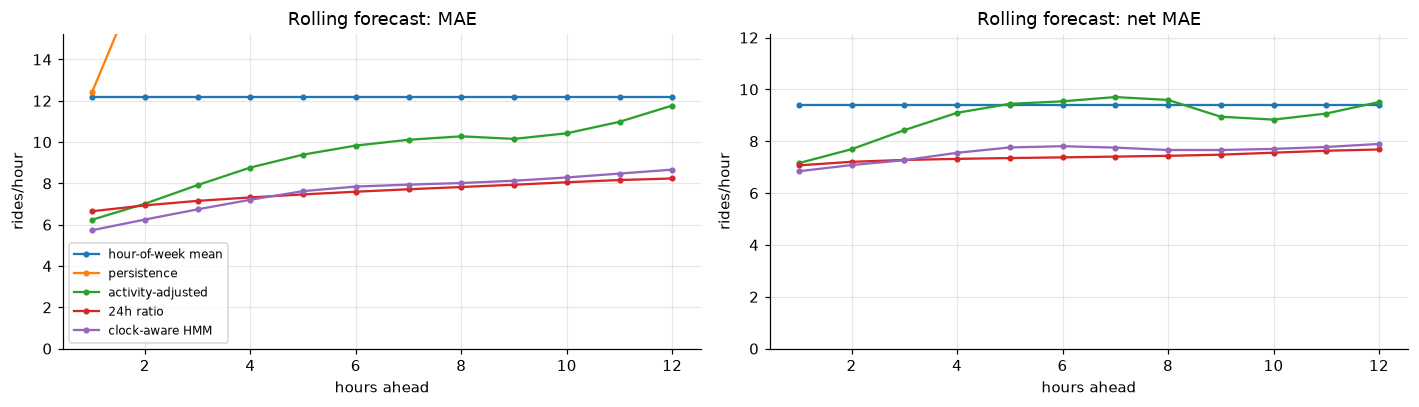

In [24]:
roll = table(wf, ["h"]).reset_index()
for metric in ["MAE", "net MAE"]:
    p = roll.pivot(index="method", columns="h", values=metric).loc[WF_METHODS]
    p["mean"] = p.mean(axis=1)
    print(f"ROLLING {metric}"); display(p[[1, 2, 3, 6, 9, 12, "mean"]].round(2))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, metric in zip(ax, ["MAE", "net MAE"]):
    for i, name in enumerate(WF_METHODS):
        q = roll[roll.method == name]; a.plot(q.h, q[metric], "o-", ms=3, color=f"C{i}", label=name)
    others = roll[roll.method != PER_][metric]
    a.set(title=f"Rolling forecast: {metric}", xlabel="hours ahead", ylabel="rides/hour", ylim=(0, others.max() * 1.25))
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

### By month

NOON MAE by month


method,hour-of-week mean,persistence,activity-adjusted,24h ratio,clock-aware HMM
month,,,,,
2025-10,12.9,25.9,9.0,9.8,8.4
2025-11,10.5,18.8,8.9,9.0,8.7
2025-12,17.5,11.7,5.7,6.2,7.6
2026-01,20.4,10.5,4.8,5.1,8.9
2026-02,23.3,7.8,3.4,4.5,6.4
2026-03,12.4,16.4,6.7,7.9,7.4
2026-04,11.2,24.3,8.6,10.3,8.6
2026-05,15.4,25.6,10.0,10.5,10.6
2026-06,17.2,24.6,11.2,10.5,10.6


months won: {'activity-adjusted': 7, 'clock-aware HMM': 4, '24h ratio': 1}


ROLLING, MEAN OVER H MAE by month


method,hour-of-week mean,persistence,activity-adjusted,24h ratio,clock-aware HMM
month,,,,,
2025-10,10.3,37.4,9.2,8.7,7.4
2025-11,8.5,27.7,8.2,7.4,7.3
2025-12,14.0,16.7,7.0,5.8,7.0
2026-01,15.4,15.2,6.5,4.5,7.7
2026-02,18.3,11.0,5.5,4.1,6.3
2026-03,9.6,23.7,6.9,6.9,6.0
2026-04,8.7,34.4,9.0,8.0,7.3
2026-05,12.1,37.2,9.7,8.0,8.4
2026-06,13.4,39.2,18.7,8.4,8.4


months won: {'clock-aware HMM': 8, '24h ratio': 4}


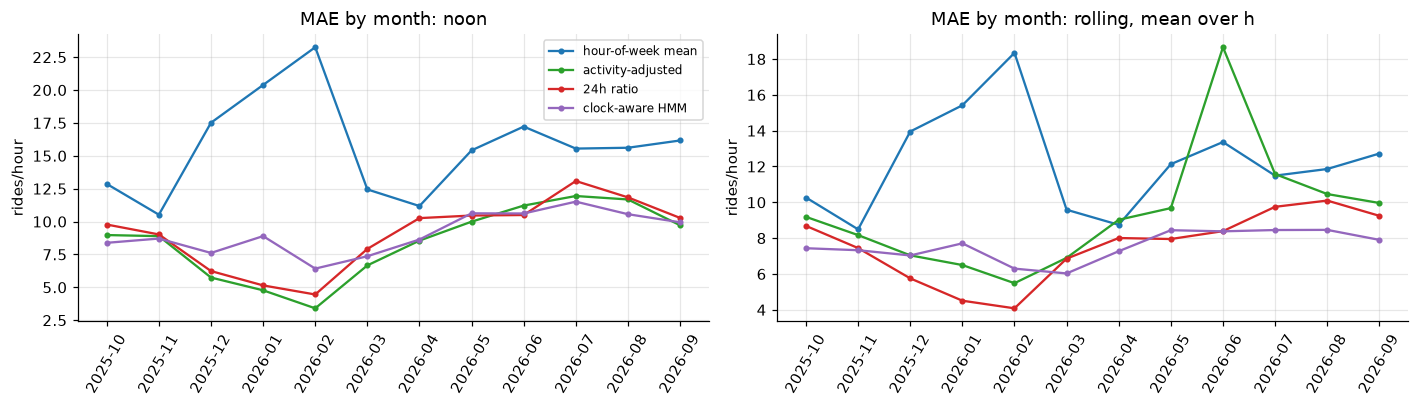

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for a, (task, df) in zip(ax, [("noon", noon), ("rolling, mean over h", wf)]):
    p = table(df, ["month"])["MAE"].unstack("method")[WF_METHODS]
    print(f"{task.upper()} MAE by month"); display(p.round(1))
    print("months won:", p.idxmin(axis=1).value_counts().to_dict())
    for i, name in enumerate(WF_METHODS):
        if name != PER_:
            a.plot(p.index.astype(str), p[name], "o-", ms=3, color=f"C{i}", label=name)
    a.set(title=f"MAE by month: {task}", ylabel="rides/hour"); a.tick_params(axis="x", rotation=60)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

### Bootstrap
Error reduction of the clock-aware HMM with 95% intervals, resampling whole weeks. n.s. = interval contains 0.

In [26]:
def boot(df, base, col, reps=4000):
    w = df[df.method.isin([HMM_, base])].groupby(["week", "method"])[col].sum().unstack()
    a, b = w[HMM_].to_numpy(), w[base].to_numpy()
    idx = np.random.default_rng(SEED).integers(0, len(w), (reps, len(w)))
    lo, hi = np.percentile(100 * (1 - a[idx].sum(1) / b[idx].sum(1)), [2.5, 97.5])
    return f"{100 * (1 - a.sum() / b.sum()):+.1f} [{lo:+.1f}, {hi:+.1f}]" + ("" if lo > 0 or hi < 0 else " n.s.")

rows = []
for task, df in {"noon": noon, **{f"rolling h={h}": wf[wf.h == h] for h in (1, 3, 6, 12)}}.items():
    for label, col in [("MAE", "abs"), ("net MAE", "net")]:
        rows.append({"task": task, "metric": label, **{f"vs {b}": boot(df, b, col) for b in WF_BASELINES}})
display(pd.DataFrame(rows).set_index(["task", "metric"]))

vs hour-of-week mean        vs persistence  \
task         metric                                                
noon         MAE      +41.7 [+36.0, +47.0]  +54.8 [+49.8, +58.6]   
             net MAE  +14.2 [+10.4, +18.3]  +54.1 [+50.3, +57.0]   
rolling h=1  MAE      +52.9 [+47.5, +58.2]  +53.8 [+50.5, +56.5]   
             net MAE  +27.2 [+21.9, +32.8]  +57.7 [+55.2, +59.7]   
rolling h=3  MAE      +44.6 [+39.0, +50.0]  +71.2 [+68.3, +73.3]   
             net MAE  +22.7 [+18.0, +27.7]  +72.1 [+69.8, +73.9]   
rolling h=6  MAE      +35.6 [+29.8, +40.9]  +74.9 [+71.8, +77.1]   
             net MAE  +16.9 [+12.2, +21.7]  +73.6 [+71.0, +75.4]   
rolling h=12 MAE      +28.9 [+24.3, +33.0]  +77.4 [+74.2, +79.7]   
             net MAE  +16.0 [+12.6, +19.5]  +74.4 [+71.7, +76.3]   

                         vs activity-adjusted             vs 24h ratio  
task         metric                                                     
noon         MAE      -7.5 [-17.3, +0.2] n.s.   -0.2 [-9.7, +7.0] n.s.  
             net MAE   -1.4 [-6.6, +2.8] n.s.        -4.8 [-9.7, -0.8]  
rolling h=1  MAE           +8.1 [+3.1, +12.5]      +13.8 [+8.9, +18.0]  
             net MAE        +4.4 [+1.8, +6.7]        +3.2 [+0.5, +5.8]  
rolling h=3  MAE          +14.8 [+7.4, +22.2]  +5.7 [-1.3, +11.5] n.s.  
             net MAE      +13.8 [+9.2, +18.2]   +0.1 [-4.3, +4.1] n.s.  
rolling h=6  MAE          +20.2 [+9.5, +30.8]  -3.3 [-13.0, +4.2] n.s.  
             net MAE     +18.2 [+11.2, +25.1]       -5.8 [-12.2, -0.8]  
rolling h=12 MAE         +26.4 [+18.4, +35.4]  -5.2 [-17.5, +4.1] n.s.  
             net MAE     +17.0 [+14.4, +19.6]   -2.8 [-9.6, +2.5] n.s.

### By hours of the day already seen

In [27]:
seen = (wf.time.dt.hour - wf.h + 1).clip(lower=0)
bins = pd.cut(seen, [-1, 0, 3, 6, 11, 23], labels=["0", "1-3", "4-6", "7-11", "12+"]).rename("hours of day seen")
by_seen = wf.groupby([bins, "method"], observed=True)[["abs", "net"]].mean().assign(abs=lambda d: d["abs"] / 2)
for col, label in [("abs", "MAE"), ("net", "net MAE")]:
    print(f"ROLLING {label} by hours of the target day already seen"); display(by_seen[col].unstack("method")[WF_METHODS].round(1))

ROLLING MAE by hours of the target day already seen


method,hour-of-week mean,persistence,activity-adjusted,24h ratio,clock-aware HMM
hours of day seen,,,,,
0,5.6,31.5,5.7,3.9,4.0
1-3,11.0,24.6,13.9,7.3,7.7
4-6,16.0,35.0,15.8,10.5,10.5
7-11,17.9,32.0,10.5,11.0,10.6
12+,13.2,26.0,7.3,7.4,7.4


ROLLING net MAE by hours of the target day already seen


method,hour-of-week mean,persistence,activity-adjusted,24h ratio,clock-aware HMM
hours of day seen,,,,,
0,6.0,24.3,6.2,4.5,4.6
1-3,9.3,18.3,11.4,7.1,7.5
4-6,12.2,21.9,12.5,9.5,9.6
7-11,12.2,48.8,9.8,9.8,9.8
12+,9.4,22.5,8.2,7.6,7.9


## 10. Convergence

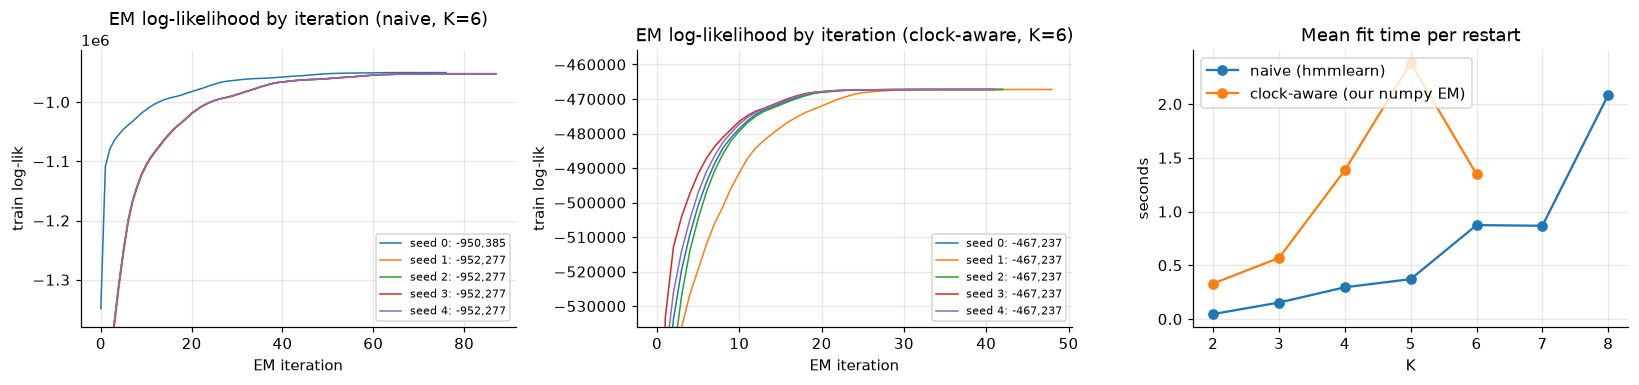

mean_iters  ll_spread_across_seeds
model       K                                    
clock-aware 2        12.0                     0.0
            3        20.0                     0.0
            4        48.2                     0.0
            5        79.8                     0.0
            6        43.8                     0.0
naive       2        13.0                     0.0
            3        31.0                     0.0
            4        45.0                   444.0
            5        43.2                   349.8
            6        85.8                  1891.6
            7        71.0                 80591.1
            8       144.6                 52473.3

In [28]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, runs, K, t in [(ax[0], runs_naive, K_naive, f"naive, K={K_naive}"), (ax[1], runs_clock, K_clock, f"clock-aware, K={K_clock}")]:
    for _, r in runs[runs.K == K].iterrows():
        a.plot(r.history, lw=1, label=f"seed {r.restart}: {r.history[-1]:,.0f}")
    a.set(title=f"EM log-likelihood by iteration ({t})", xlabel="EM iteration", ylabel="train log-lik"); a.legend(fontsize=7)
    lo = min(r.history[min(3, len(r.history) - 1)] for _, r in runs[runs.K == K].iterrows())
    a.set_ylim(bottom=lo)
for runs, lbl in [(runs_naive, "naive (hmmlearn)"), (runs_clock, "clock-aware (our numpy EM)")]:
    ax[2].plot(runs.groupby("K").seconds.mean(), "o-", label=lbl)
ax[2].set(title="Mean fit time per restart", xlabel="K", ylabel="seconds"); ax[2].legend()
plt.tight_layout(); plt.show()

conv = pd.concat([r.assign(model=n) for n, r in [("naive", runs_naive), ("clock-aware", runs_clock)]])
display(conv.groupby(["model", "K"]).agg(mean_iters=("iters", "mean"), ll_spread_across_seeds=("train_ll", lambda s: s.max() - s.min())).round(1))

## References
* Citi Bike System Data: https://citibikenyc.com/system-data
* hmmlearn documentation: https://hmmlearn.readthedocs.io